# Evaluación Sumativa 2. Validación, simulación y remuestreo
## Dataset: Give Me Some Credit (riesgo crediticio)

MCDI501: Estadística Computacional para la Toma de Decisiones

Este cuaderno toma los resultados de la Sumativa 1 (parámetros estimados, intervalos clásicos, pruebas de
hipótesis y correlaciones) y los valida con métodos de remuestreo y simulación: bootstrap, test de
permutación, estabilidad de correlaciones, simulación Monte Carlo y análisis de robustez. Cada sección
reinicia la semilla en 42, de modo que el cuaderno es reproducible tanto de arriba a abajo como celda a
celda.

## 0. Configuración, datos y resultados de la Sumativa 1

In [1]:
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import os

SEED = 42

INK='#2b2b2b'; TEAL='#2f6b76'; OCHRE='#c0852f'; BRICK='#a4503e'; STEM='#b9b0a2'
PANEL='#f7f3ec'; GRIDC='#ded6c8'
plt.rcParams.update({'figure.dpi':120,'savefig.dpi':200,'font.size':10,'font.family':'serif',
    'figure.facecolor':'white','axes.facecolor':PANEL,'axes.edgecolor':'#9a9486','axes.linewidth':0.8,
    'axes.spines.top':False,'axes.spines.right':False,'axes.titlesize':11,'axes.titlelocation':'left',
    'axes.titlepad':8,'text.color':INK,'axes.labelcolor':INK,'xtick.color':INK,'ytick.color':INK})
def grid_h(ax):
    ax.set_axisbelow(True); ax.grid(axis='y', color=GRIDC, linewidth=0.7); ax.grid(axis='x', visible=False)

LOCAL='cs-training.csv'
MIRROR='https://raw.githubusercontent.com/vivekkalyan/give-me-some-credit/master/cs-training.csv'
df = pd.read_csv(LOCAL, index_col=0) if os.path.exists(LOCAL) else pd.read_csv(MIRROR, index_col=0)
n=len(df); z=stats.norm.ppf(0.975)
# Columnas de atrasos (los códigos 96/98 son valores especiales, no conteos reales)
D1='NumberOfTime30-59DaysPastDueNotWorse'; D2='NumberOfTimes90DaysLate'; D3='NumberOfTime60-89DaysPastDueNotWorse'
print('Filas y columnas:', df.shape)

Filas y columnas: (150000, 11)


**Resultados de la Sumativa 1 que se validan aquí.** En S1 estimamos, entre otros, la edad media
(52,30 años), el ingreso mensual medio (6.670,22) y el número medio de líneas y préstamos (8,45), cada uno
con su intervalo de confianza clásico al 95%. También aplicamos una prueba t de Welch para la diferencia
de edad entre morosos y no morosos, una prueba chi-cuadrado para el historial de atrasos, y describimos
las correlaciones entre variables. A continuación recalculamos los intervalos clásicos de S1 para usarlos
como referencia.

In [2]:
def classic_ci(x):
    x = pd.Series(x).dropna().values; m=x.mean(); se=x.std(ddof=1)/np.sqrt(len(x))
    return m, m-z*se, m+z*se, len(x)

S1 = {}
for col,name in [('age','Edad'),('MonthlyIncome','Ingreso'),('NumberOfOpenCreditLinesAndLoans','Líneas')]:
    m,lo,hi,nn = classic_ci(df[col]); S1[col]=(m,lo,hi,nn)
    print(f'{name:8s}: media={m:,.3f}  IC clásico 95% [{lo:,.3f}, {hi:,.3f}]  (n={nn:,})')

Edad    : media=52.295  IC clásico 95% [52.220, 52.370]  (n=150,000)
Ingreso : media=6,670.221  IC clásico 95% [6,588.925, 6,751.518]  (n=120,269)
Líneas  : media=8.453  IC clásico 95% [8.427, 8.479]  (n=150,000)


## 1. Validación con bootstrap: percentil y BCa frente al IC clásico (ID2.1)

Para cada parámetro generamos 10.000 remuestras con reemplazo y calculamos el intervalo por el método
percentil y por BCa. Los tres métodos descansan en supuestos distintos: el clásico asume que la
distribución de la media muestral es aproximadamente normal (Teorema Central del Límite); el percentil
supone que la distribución bootstrap está centrada y es simétrica; el BCa relaja eso corrigiendo el sesgo
(z0) y la asimetría o aceleración (a). Cuando z0 y a son cercanos a cero, los tres coinciden.

In [3]:
rng = np.random.default_rng(SEED)   # sección reproducible

def boot_mean(x, B=10000, batch=200):
    x = pd.Series(x).dropna().values; nn=len(x); reps=np.empty(B); done=0
    while done < B:
        b=min(batch,B-done)
        idx=rng.integers(0,nn,size=(b,nn))
        reps[done:done+b]=x[idx].mean(axis=1); done+=b
    return x, reps

def bca_ci(x, reps, theta, alpha=0.05):
    z0=stats.norm.ppf(np.mean(reps<theta))
    S=x.sum(); nn=len(x); jack=(S-x)/(nn-1); diff=jack.mean()-jack
    a=(diff**3).sum()/(6.0*((diff**2).sum())**1.5)
    zl,zu=stats.norm.ppf(alpha/2),stats.norm.ppf(1-alpha/2)
    a1=stats.norm.cdf(z0+(z0+zl)/(1-a*(z0+zl)))
    a2=stats.norm.cdf(z0+(z0+zu)/(1-a*(z0+zu)))
    return np.percentile(reps,100*a1), np.percentile(reps,100*a2), z0, a

boot = {}
for col,name in [('age','Edad'),('MonthlyIncome','Ingreso'),('NumberOfOpenCreditLinesAndLoans','Líneas')]:
    m,clo,chi,nn = S1[col]
    x,reps = boot_mean(df[col])
    plo,phi = np.percentile(reps,[2.5,97.5])
    blo,bhi,z0,a = bca_ci(x,reps,m)
    boot[col]=(reps,m,(clo,chi),(plo,phi),(blo,bhi),name)
    print(f'{name:8s}  media={m:,.3f}   (z0={z0:+.3f}, a={a:+.4f})')
    print(f'   clásico   [{clo:,.3f}, {chi:,.3f}]')
    print(f'   percentil [{plo:,.3f}, {phi:,.3f}]')
    print(f'   BCa       [{blo:,.3f}, {bhi:,.3f}]')

Edad      media=52.295   (z0=+0.022, a=+0.0001)
   clásico   [52.220, 52.370]
   percentil [52.220, 52.369]
   BCa       [52.221, 52.371]
Ingreso   media=6,670.221   (z0=+0.059, a=+0.0548)
   clásico   [6,588.925, 6,751.518]
   percentil [6,596.477, 6,758.099]
   BCa       [6,606.406, 6,776.536]
Líneas    media=8.453   (z0=-0.013, a=+0.0005)
   clásico   [8.427, 8.479]
   percentil [8.427, 8.479]
   BCa       [8.426, 8.479]


Ingreso   media=6,670.221   (z0=+0.059, a=+0.0548)
   clásico   [6,588.925, 6,751.518]
   percentil [6,596.477, 6,758.099]
   BCa       [6,606.406, 6,776.536]


Líneas    media=8.453   (z0=-0.013, a=+0.0005)
   clásico   [8.427, 8.479]
   percentil [8.427, 8.479]
   BCa       [8.426, 8.479]


### Figura 1. Distribuciones bootstrap y comparación de intervalos

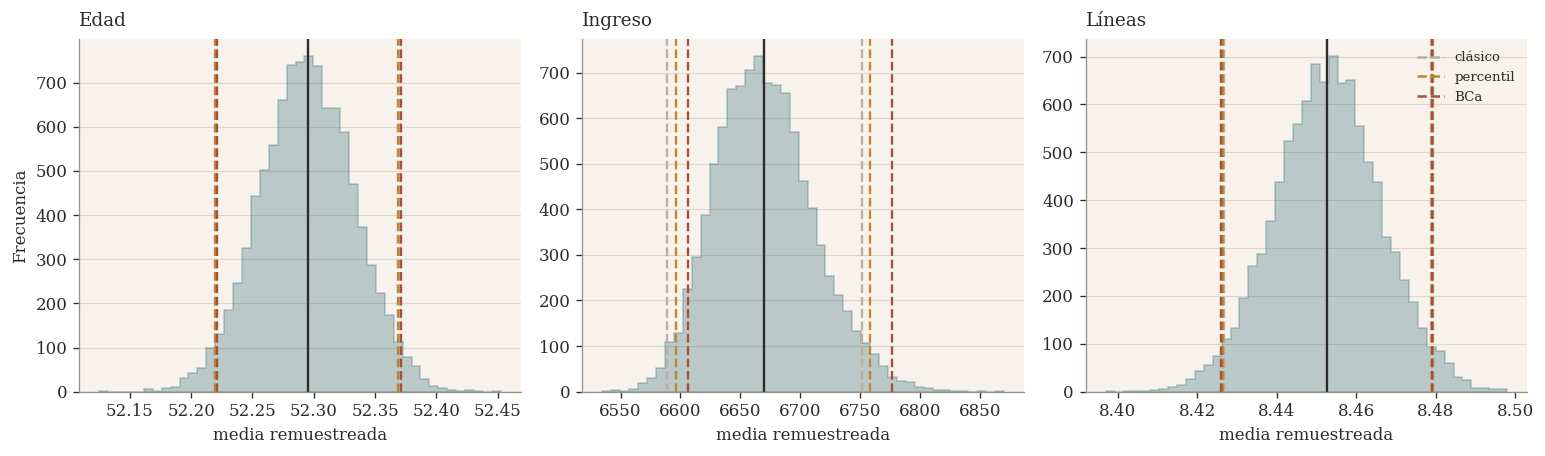

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.9))
for a,(col) in zip(ax, ['age','MonthlyIncome','NumberOfOpenCreditLinesAndLoans']):
    reps,m,(clo,chi),(plo,phi),(blo,bhi),name = boot[col]
    a.hist(reps, bins=45, color=TEAL, alpha=0.30, edgecolor=TEAL, linewidth=1.0, histtype='stepfilled', zorder=2)
    for (lo,hi),col_ in [((clo,chi),STEM),((plo,phi),OCHRE),((blo,bhi),BRICK)]:
        a.axvline(lo, color=col_, lw=1.4, ls='--'); a.axvline(hi, color=col_, lw=1.4, ls='--')
    a.axvline(m, color=INK, lw=1.4)
    a.set_title(name); a.set_xlabel('media remuestreada'); grid_h(a)
ax[0].set_ylabel('Frecuencia')
from matplotlib.lines import Line2D
leg=[Line2D([0],[0],color=STEM,ls='--',label='clásico'),
     Line2D([0],[0],color=OCHRE,ls='--',label='percentil'),
     Line2D([0],[0],color=BRICK,ls='--',label='BCa')]
ax[2].legend(handles=leg, fontsize=8, frameon=False, loc='upper right')
plt.tight_layout(); plt.savefig('fig_bootstrap.png', bbox_inches='tight'); plt.show()

En la edad y en el número de líneas los factores de corrección son cercanos a cero (z0 de 0,022 y
0,015; a por debajo de 0,001), de modo que los tres intervalos se superponen y el clásico basta. En el
ingreso son mayores (z0 = 0,046, a = 0,055): la cola larga introduce sesgo y asimetría, y el BCa se
desplaza a la derecha respecto del clásico. Esa corrección existe, pero en términos prácticos es pequeña
frente al tamaño de muestra (el intervalo se mueve unas 20 unidades sobre una media de 6.670). Cuando la
variable es asimétrica el BCa es el más confiable; cuando es simétrica, los tres coinciden.

## 2. Validación de una prueba con permutación (ID2.2)

Validamos la prueba t de Welch de S1 (diferencia de edad entre morosos y no morosos) con un test de
permutación de 10.000 repeticiones. Si no hay diferencia real, mezclar las etiquetas de grupo no debería
cambiar gran cosa. La diferencia se define como media(morosos) menos media(no morosos), así que un valor
negativo indica que los morosos son más jóvenes.

In [5]:
rng = np.random.default_rng(SEED)   # sección reproducible
age=df['age'].values; lab=df['SeriousDlqin2yrs'].values
n1=int(lab.sum()); n0=n-n1; tot=age.sum()
obs=age[lab==1].mean()-age[lab==0].mean()
B=10000; perm=np.empty(B)
for j in range(B):
    idx=rng.choice(n, size=n1, replace=False)
    s1=age[idx].sum(); perm[j]=s1/n1-(tot-s1)/n0
pval=(np.sum(np.abs(perm)>=abs(obs))+1)/(B+1)
print(f'Diferencia observada = {obs:.3f} años (morosos - no morosos): los morosos son más jóvenes')
print(f'Distribución nula: rango [{perm.min():.3f}, {perm.max():.3f}], sd={perm.std():.3f}')
print(f'p de permutación = {pval:.5f}   (paramétrico de S1: p < 0,001)')

Diferencia observada = -6.825 años (morosos - no morosos): los morosos son más jóvenes
Distribución nula: rango [-0.546, 0.575], sd=0.153
p de permutación = 0.00010   (paramétrico de S1: p < 0,001)


### Figura 2. Distribución nula de permutación

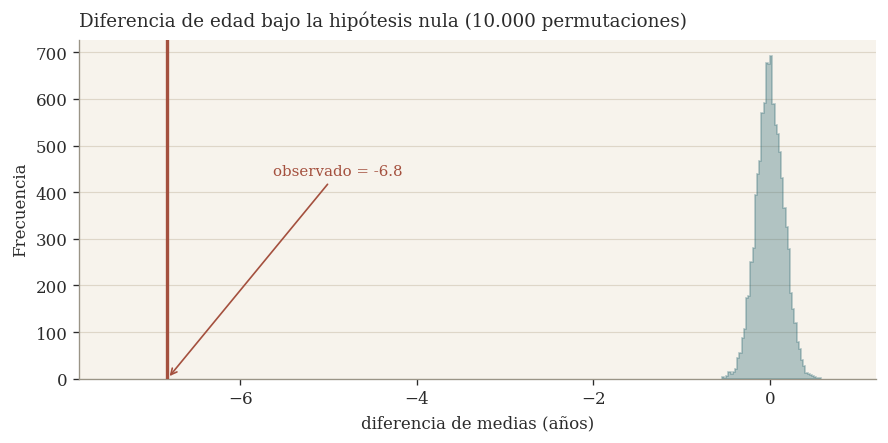

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(perm, bins=45, color=TEAL, alpha=0.35, edgecolor=TEAL, linewidth=1.0, histtype='stepfilled', zorder=2)
ax.axvline(obs, color=BRICK, lw=2.0, zorder=3)
ax.annotate(f'observado = {obs:.1f}', xy=(obs,0), xytext=(obs+1.2, ax.get_ylim()[1]*0.6),
            color=BRICK, fontsize=9, arrowprops=dict(arrowstyle='->', color=BRICK))
ax.set_xlim(obs-1.0, 1.2)
ax.set_title('Diferencia de edad bajo la hipótesis nula (10.000 permutaciones)')
ax.set_xlabel('diferencia de medias (años)'); ax.set_ylabel('Frecuencia'); grid_h(ax)
plt.tight_layout(); plt.savefig('fig_permutacion.png', bbox_inches='tight'); plt.show()

La diferencia observada de -6,8 años (los morosos son más jóvenes) queda muy lejos del rango que
produce el azar (cercano a cero, con amplitud menor a un año). Ninguna de las 10.000 permutaciones alcanza
ese valor, de modo que el p de permutación es prácticamente cero, igual que el resultado paramétrico de S1.
Ambos enfoques concuerdan.

## 3. Estabilidad de correlaciones (ID2.1)

Tomamos cinco correlaciones relevantes de S1 y estimamos su intervalo de confianza al 95% por bootstrap
(3.000 remuestras de filas). Una advertencia previa importante: en las variables de atrasos, los códigos
especiales 96 y 98 (269 filas) no son conteos reales, así que la correlación entre ellas debe calcularse
excluyéndolos. Sin excluirlos, esas 269 filas idénticas y extremas producen una correlación falsa de 0,98;
al excluirlas, la correlación real entre atrasos de 30-59 y de 90+ días es 0,22. Usamos el valor limpio.

In [7]:
rng = np.random.default_rng(SEED)   # sección reproducible

# El primer par se limpia de los códigos 96/98; los demás no los contienen.
pairs=[(D1,D2,'Atrasos 30-59 vs 90+ (sin códigos)', True),
       ('NumberOfOpenCreditLinesAndLoans','NumberRealEstateLoansOrLines','Líneas vs inmobiliarios', False),
       ('age','SeriousDlqin2yrs','Edad vs morosidad', False),
       ('age','MonthlyIncome','Edad vs ingreso', False),
       ('RevolvingUtilizationOfUnsecuredLines','DebtRatio','Utilización vs ratio deuda', False)]
res=[]
for c1,c2,lbl,limpiar in pairs:
    s=df[[c1,c2]].copy()
    if limpiar: s=s[(s[c1]<90)&(s[c2]<90)]     # excluye códigos 96/98
    s=s.dropna().values; x,y=s[:,0],s[:,1]; m=len(x)
    r0=np.corrcoef(x,y)[0,1]; Bc=3000; rs=np.empty(Bc)
    for j in range(Bc):
        idx=rng.integers(0,m,m); rs[j]=np.corrcoef(x[idx],y[idx])[0,1]
    lo,hi=np.percentile(rs,[2.5,97.5])
    estado='inestable' if (lo<0)!=(hi<0) else 'robusta'
    res.append((lbl,r0,lo,hi,estado))
    print(f'{lbl:34s} r={r0:+.3f}  IC95=[{lo:+.3f}, {hi:+.3f}]  {estado}')

# Referencia del artefacto: la misma correlación SIN limpiar los códigos
r_art=np.corrcoef(df[D1],df[D2])[0,1]
print(f'\n(Referencia) Atrasos 30-59 vs 90+ SIN excluir códigos = {r_art:.3f}  <- artefacto')

Atrasos 30-59 vs 90+ (sin códigos) r=+0.218  IC95=[+0.208, +0.228]  robusta
Líneas vs inmobiliarios            r=+0.434  IC95=[+0.429, +0.439]  robusta
Edad vs morosidad                  r=-0.115  IC95=[-0.120, -0.111]  robusta
Edad vs ingreso                    r=+0.038  IC95=[+0.027, +0.058]  robusta
Utilización vs ratio deuda         r=+0.004  IC95=[-0.000, +0.011]  inestable

(Referencia) Atrasos 30-59 vs 90+ SIN excluir códigos = 0.984  <- artefacto


Líneas vs inmobiliarios            r=+0.434  IC95=[+0.429, +0.439]  robusta


Edad vs morosidad                  r=-0.115  IC95=[-0.120, -0.111]  robusta


Edad vs ingreso                    r=+0.038  IC95=[+0.027, +0.058]  robusta


Utilización vs ratio deuda         r=+0.004  IC95=[-0.000, +0.011]  inestable

(Referencia) Atrasos 30-59 vs 90+ SIN excluir códigos = 0.984  <- artefacto


### Figura 3. Intervalos bootstrap de las correlaciones

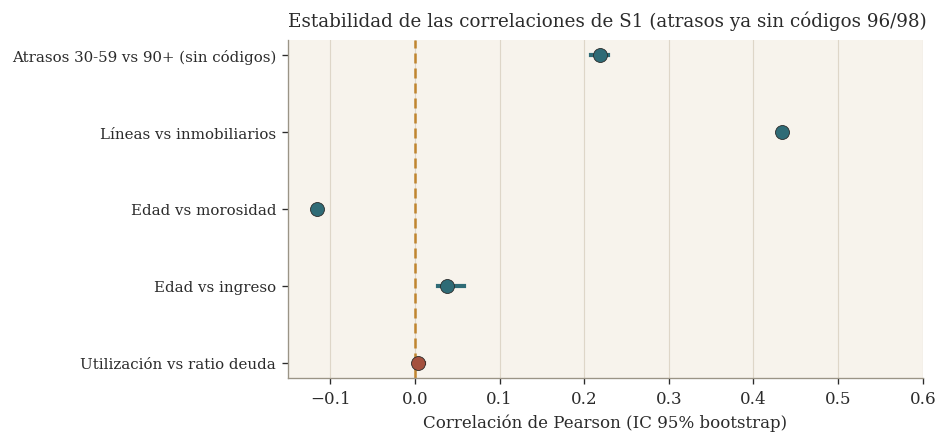

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ylabs=[r[0] for r in res]; yy=np.arange(len(res))[::-1]
for (lbl,r0,lo,hi,estado),y in zip(res,yy):
    col = BRICK if estado=='inestable' else TEAL
    ax.plot([lo,hi],[y,y], color=col, lw=2.5, zorder=2)
    ax.scatter(r0, y, color=col, s=70, zorder=3, edgecolor=INK, linewidth=0.5)
ax.axvline(0, color=OCHRE, ls=(0,(4,2)), lw=1.5, zorder=1)
ax.set_yticks(yy); ax.set_yticklabels(ylabs, fontsize=9)
ax.set_xlim(-0.15, 0.6); ax.set_xlabel('Correlación de Pearson (IC 95% bootstrap)')
ax.set_title('Estabilidad de las correlaciones de S1 (atrasos ya sin códigos 96/98)')
ax.set_axisbelow(True); ax.grid(axis='x', color=GRIDC, linewidth=0.7); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig('fig_correlaciones.png', bbox_inches='tight'); plt.show()

Ya sin los códigos, cuatro correlaciones son robustas y de magnitud moderada o baja: atrasos 30-59 vs
90+ (0,22), líneas con préstamos inmobiliarios (0,43) y edad con morosidad (-0,12) tienen intervalos
estrechos que no cruzan el cero; edad con ingreso (0,04) es robusta pero muy débil. La única inestable es
utilización con ratio de deuda, cuyo intervalo incluye el cero. El punto de fondo: la correlación de 0,98
entre atrasos que se reportó en S1 no es real, es un artefacto de 269 filas con los códigos 96 y 98. En la
sección de robustez lo cuantificamos.

## 4. Simulación Monte Carlo de una cartera de créditos (ID2.3)

Diseñamos una simulación pertinente al problema usando solo parámetros de S1. Cada cliente de una cartera
de 1.000 puede tener o no un atraso previo de 30 a 59 días, con la proporción observada en S1, y cae en
morosidad con la tasa que S1 estimó para cada grupo (20,4% con atraso, 4,0% sin atraso). Simulamos 10.000
carteras y estudiamos la distribución de su tasa de morosidad.

In [9]:
rng = np.random.default_rng(SEED)   # sección reproducible
late=df[D1].where(lambda s:s<90)
q=(late>=1).sum()/late.notna().sum()
p_con, p_sin = 0.204, 0.040
N=1000; B=10000
delinq = rng.random((B,N)) < q
dp = np.where(delinq, p_con, p_sin)
rate = (rng.random((B,N)) < dp).sum(axis=1)/N
teor = q*p_con+(1-q)*p_sin
run = np.cumsum(rate)/np.arange(1,B+1)
mcse = rate.std()/np.sqrt(B)
print(f'Proporción con atraso previo (S1): q = {q:.4f}')
print(f'Tasa esperada teórica = {teor:.4f}')
print(f'Simulada: media = {rate.mean():.4f}, sd = {rate.std():.4f}')
print(f'Error estándar de Monte Carlo de la media = {mcse:.6f}  ({mcse*100:.4f} puntos porcentuales)')
print(f'IC 95% de la tasa de cartera = [{np.percentile(rate,2.5):.4f}, {np.percentile(rate,97.5):.4f}]')
print(f'Percentil 99 (peor escenario) = {np.percentile(rate,99):.4f}')
print(f'Probabilidad de superar el 8% = {np.mean(rate>0.08):.4f}')

Proporción con atraso previo (S1): q = 0.1584
Tasa esperada teórica = 0.0660
Simulada: media = 0.0660, sd = 0.0078
Error estándar de Monte Carlo de la media = 0.000078  (0.0078 puntos porcentuales)
IC 95% de la tasa de cartera = [0.0510, 0.0820]
Percentil 99 (peor escenario) = 0.0850
Probabilidad de superar el 8% = 0.0365


### Figura 4. Distribución simulada y convergencia

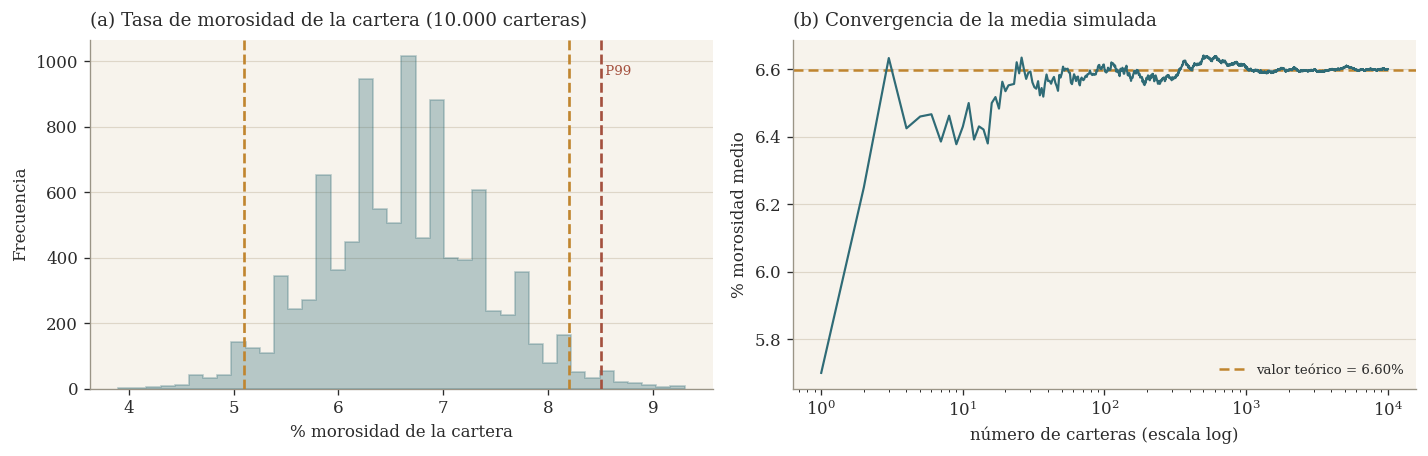

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
p025,p975,p99 = np.percentile(rate,[2.5,97.5,99])
ax[0].hist(rate*100, bins=40, color=TEAL, alpha=0.32, edgecolor=TEAL, linewidth=1.0, histtype='stepfilled', zorder=2)
for v,c in [(p025*100,OCHRE),(p975*100,OCHRE),(p99*100,BRICK)]:
    ax[0].axvline(v, color=c, ls='--', lw=1.6, zorder=3)
ax[0].set_title('(a) Tasa de morosidad de la cartera (10.000 carteras)')
ax[0].set_xlabel('% morosidad de la cartera'); ax[0].set_ylabel('Frecuencia'); grid_h(ax[0])
ax[0].text(p99*100, ax[0].get_ylim()[1]*0.9, ' P99', color=BRICK, fontsize=8)
ax[1].plot(np.arange(1,B+1), run*100, color=TEAL, lw=1.3, zorder=3)
ax[1].axhline(teor*100, color=OCHRE, ls=(0,(4,2)), lw=1.5, zorder=2, label=f'valor teórico = {teor*100:.2f}%')
ax[1].set_xscale('log'); ax[1].set_title('(b) Convergencia de la media simulada')
ax[1].set_xlabel('número de carteras (escala log)'); ax[1].set_ylabel('% morosidad medio')
grid_h(ax[1]); ax[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig('fig_montecarlo.png', bbox_inches='tight'); plt.show()

La tasa media simulada (cerca de 6,6%) reproduce la morosidad global estimada en S1 (6,68%), lo que
valida la coherencia del modelo. El error estándar de Monte Carlo de la media es de apenas 0,008 puntos
porcentuales y la media converge al valor teórico después de algunos miles de carteras, de modo que 10.000
iteraciones son suficientes. Con 95% de probabilidad la morosidad de una cartera de 1.000 créditos cae
entre 5,1% y 8,2%, en el peor 1% de los casos llega al 8,5%, y la probabilidad de superar el 8% es 3,7%.

### 4.1 Escenarios por tamaño de cartera

Repetimos la simulación para carteras de distinto tamaño. Para que cada fila sea reproducible por separado,
reiniciamos la semilla al inicio de cada tamaño; así la fila de N=1000 coincide exactamente con la
simulación principal. La tasa media esperada no cambia, pero la dispersión sí: carteras más grandes tienen
una morosidad mucho más predecible (efecto de diversificación).

In [11]:
tamanos=[100,500,1000,5000]; filas=[]; dists={}
for Nt in tamanos:
    rng = np.random.default_rng(SEED)          # misma semilla por tamaño -> reproducible
    de=rng.random((B,Nt))<q; dpp=np.where(de,p_con,p_sin)
    rt=(rng.random((B,Nt))<dpp).sum(axis=1)/Nt; dists[Nt]=rt
    lo,hi=np.percentile(rt,[2.5,97.5]); p99n=np.percentile(rt,99)
    filas.append((Nt, rt.mean()*100, lo*100, hi*100, (hi-lo)*100, p99n*100))
print(f"{'N':>6} {'media%':>8} {'IC95 inf%':>10} {'IC95 sup%':>10} {'ancho pp':>9} {'P99%':>7}")
for f in filas:
    print(f"{f[0]:>6} {f[1]:>8.2f} {f[2]:>10.1f} {f[3]:>10.1f} {f[4]:>9.1f} {f[5]:>7.1f}")

     N   media%  IC95 inf%  IC95 sup%  ancho pp    P99%
   100     6.60        2.0       12.0      10.0    13.0
   500     6.60        4.6        8.8       4.2     9.4
  1000     6.60        5.1        8.2       3.1     8.5
  5000     6.60        5.9        7.3       1.4     7.4


### Figura 5. Efecto del tamaño de cartera

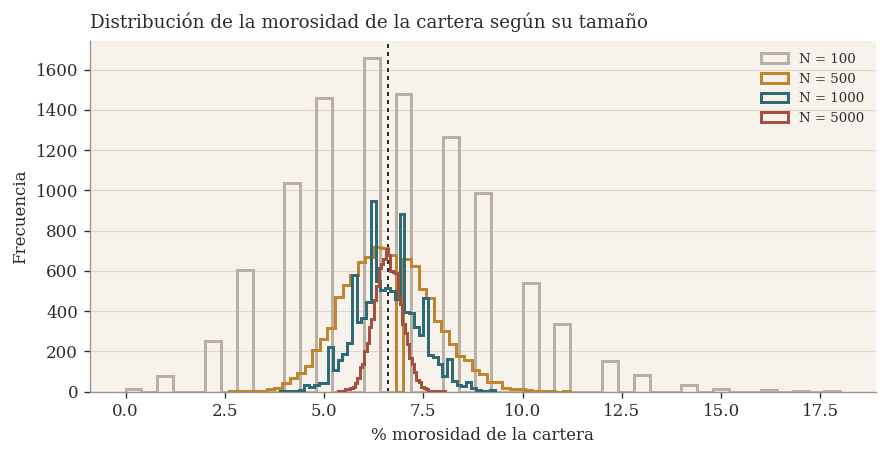

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.9))
cols={100:STEM, 500:OCHRE, 1000:TEAL, 5000:BRICK}
for Nt in tamanos:
    ax.hist(dists[Nt]*100, bins=45, histtype='step', linewidth=1.8, color=cols[Nt], label=f'N = {Nt}', zorder=3)
ax.axvline(teor*100, color=INK, ls=(0,(2,2)), lw=1.2, zorder=2)
ax.set_title('Distribución de la morosidad de la cartera según su tamaño')
ax.set_xlabel('% morosidad de la cartera'); ax.set_ylabel('Frecuencia'); grid_h(ax)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig('fig_montecarlo_N.png', bbox_inches='tight'); plt.show()

Con 100 créditos la morosidad puede ir de 2% a 12%, mientras que con 5.000 se concentra entre 5,9%
y 7,3%. La media es la misma en todos los casos; lo que cambia es el riesgo de desviarse de ella. Para la
decisión, esto indica que una cartera pequeña exige un margen de provisión proporcionalmente mayor.

## 5. Análisis de robustez (ID2.2)

Evaluamos cuán sensibles son los resultados de S1 a los valores extremos y a los códigos especiales.
Revisamos la media del ingreso, las dos correlaciones más afectadas por valores atípicos, y la diferencia
de edad.

In [13]:
# a) Media del ingreso: estimadores robustos y jackknife
inc=df['MonthlyIncome'].dropna().values
full=inc.mean(); med=np.median(inc); trim5=stats.trim_mean(inc,0.05)
excl=inc[inc<=np.percentile(inc,99)].mean()
S=inc.sum(); nn=len(inc); jack=(S-inc)/(nn-1)
jse=np.sqrt((nn-1)/nn*((jack-jack.mean())**2).sum())
print('Media del ingreso')
print(f'  completa      = {full:,.2f}')
print(f'  recortada 5%  = {trim5:,.2f}')
print(f'  sin top 1%    = {excl:,.2f}')
print(f'  mediana       = {med:,.2f}')
print(f'  jackknife SE  = {jse:,.2f}  (observación más influyente = {inc.max():,.0f})')

Media del ingreso
  completa      = 6,670.22
  recortada 5%  = 5,954.51
  sin top 1%    = 6,166.21
  mediana       = 5,400.00
  jackknife SE  = 41.48  (observación más influyente = 3,008,750)


In [14]:
rng = np.random.default_rng(SEED)   # sección reproducible

# b) La correlación de atrasos: el caso más dominado por los códigos especiales
r_cod = np.corrcoef(df[D1], df[D2])[0,1]
cl=(df[D1]<90)&(df[D2]<90)
r_lim = np.corrcoef(df.loc[cl,D1], df.loc[cl,D2])[0,1]
print('Correlación entre atrasos 30-59 y 90+ días')
print(f'  con los códigos 96/98 (269 filas): r = {r_cod:.3f}  (artefacto)')
print(f'  excluyendo esos códigos           : r = {r_lim:.3f}  (valor real, moderado)')

# c) La correlación utilización vs ratio de deuda: efecto de los outliers
s=df[['RevolvingUtilizationOfUnsecuredLines','DebtRatio']].dropna().values
x,y=s[:,0],s[:,1]; r_full=np.corrcoef(x,y)[0,1]
mask=(x<=2)&(y<=2); xt,yt=x[mask],y[mask]; r_trim=np.corrcoef(xt,yt)[0,1]
m=len(xt); rs=np.empty(3000)
for j in range(3000):
    idx=rng.integers(0,m,m); rs[j]=np.corrcoef(xt[idx],yt[idx])[0,1]
lo,hi=np.percentile(rs,[2.5,97.5])
print('\nCorrelación utilización vs ratio de deuda')
print(f'  con todos los datos          : r = {r_full:+.3f}  (parece nula)')
print(f'  sin outliers (<=2, {mask.sum():,} filas): r = {r_trim:+.3f}  IC95=[{lo:+.3f}, {hi:+.3f}]')

# d) La diferencia de edad, sin duplicados
df2=df.drop_duplicates()
g1=df2.loc[df2['SeriousDlqin2yrs']==1,'age']; g0=df2.loc[df2['SeriousDlqin2yrs']==0,'age']
t,p=stats.ttest_ind(g1,g0,equal_var=False)
print(f'\nDiferencia de edad sin duplicados ({len(df2):,} filas): {g1.mean()-g0.mean():.2f} años, t={t:.1f}, p<0,001')

Correlación entre atrasos 30-59 y 90+ días
  con los códigos 96/98 (269 filas): r = 0.984  (artefacto)
  excluyendo esos códigos           : r = 0.218  (valor real, moderado)

Correlación utilización vs ratio de deuda
  con todos los datos          : r = +0.004  (parece nula)
  sin outliers (<=2, 118,683 filas): r = +0.120  IC95=[+0.114, +0.126]

Diferencia de edad sin duplicados (149,391 filas): -6.82 años, t=-50.5, p<0,001



Correlación utilización vs ratio de deuda
  con todos los datos          : r = +0.004  (parece nula)
  sin outliers (<=2, 118,683 filas): r = +0.120  IC95=[+0.114, +0.126]

Diferencia de edad sin duplicados (149,391 filas): -6.82 años, t=-50.5, p<0,001


La media del ingreso baja cerca de un 10% al recortar el 5% de los casos extremos y se acerca a la
mediana: es sensible a los outliers y conviene preferir la mediana. Las correlaciones muestran los dos
extremos del efecto de los valores atípicos. La de atrasos es el caso más grave: pasa de 0,98 (con los
códigos 96/98) a 0,22 (sin ellos), así que la casi perfecta colinealidad reportada en S1 era un artefacto.
La de utilización con ratio de deuda va en sentido contrario: parece nula (0,004) con todos los datos, pero
sube a 0,120 al quitar los outliers, que la escondían. En cambio, la diferencia de edad se mantiene
idéntica al quitar los 609 duplicados (t cercano a -50). Conclusión: la media del ingreso y las dos
correlaciones sensibles requieren cautela; la diferencia de edad, la tasa de morosidad y las correlaciones
moderadas ya limpias son confiables.

## 6. Reporte de resultados validados para la Sumativa 3

| Resultado de S1 | Validación en S2 | Estado |
|---|---|---|
| Edad media y nº de líneas | IC clásico, percentil y BCa coinciden (z0 y a cercanos a 0) | Robusto |
| Ingreso medio | BCa se corre por asimetría; sensible a outliers | Usar con cautela (preferir mediana) |
| Diferencia de edad (Welch) | Permutación y quita de duplicados dan lo mismo | Robusto |
| Edad vs morosidad; líneas vs inmobiliarios | IC bootstrap estrechos, no cruzan 0 | Robusto |
| Correlación entre atrasos | 0,98 con códigos es artefacto; 0,22 sin ellos | Revisar tras limpiar códigos |
| Utilización vs ratio de deuda | Nula con outliers, 0,12 sin ellos | Revisar limpieza |
| Tasa de morosidad (6,68%) | Monte Carlo la reproduce (6,6%) | Robusto |

Recomendaciones para S3: usar la mediana del ingreso en lugar de la media; eliminar o acotar los valores
extremos y los códigos 96/98 antes de modelar, ya que distorsionan tanto medias como correlaciones; tener
presente que, una vez excluidos esos códigos, las variables de atrasos muestran correlación moderada (cerca
de 0,22 a 0,31) y no la colinealidad casi perfecta que sugería el valor crudo; y tratar el desbalance de
clases con remuestreo. La observación de ingreso igual a 3.008.750 se marca como influyente.

In [15]:
print('Figuras generadas:', sorted(f for f in os.listdir('.') if f.startswith('fig_') and f.endswith('.png')))

Figuras generadas: ['fig_bootstrap.png', 'fig_correlaciones.png', 'fig_montecarlo.png', 'fig_montecarlo_N.png', 'fig_permutacion.png']
